# Ingestão e análise - Antecipação de Recebíveis da Olist

O objetivo desse mini-projeto é aplicar os conceitos de **Engenharia e Análise de Dados** para estudo e construção de portfólio.\
Abaixo um pipeline de dados (camadas **bronze → silver → gold**) foi montado completamente usando os recursos do Databricks com scripts em **Python, PySpark e SQL**.\
\
**Dataset utilizado**: Kaggle -  [Brazilian E-Commerce Public Dataset by Olist](https://www.kaggle.com/datasets/olistbr/brazilian-ecommerce)

## Regras de negócio

Não são premissas de mercado (taxas, MDR, custo de captação de dinheiro): são regras de construção da agenda e cortes da segmentação. Ficam aqui para que nenhum número apareça "solto" no código.

In [0]:
# Agenda: a parcela k de uma venda no crédito liquida em D + 30·k.
PRAZO_DIAS_PARCELA = 30

# Segmentação por regra (Etapa 3). Ajuste depois de olhar as distribuições e registre o motivo.
SEG_TOP_AGENDA = 0.20 # top 20% dos lojistas por agenda em aberto
SEG_MIN_PARCELADO = 0.50 # > 50% do TPV no crédito parcelado = "grande parcelador"
SEG_MAX_PARCELADO_AVISTA = 0.20 # < 20% do TPV parcelado = "à vista"
SEG_MIN_MESES_ATIVOS = 3 # vendas em pelo menos 3 meses...
SEG_JANELA_MESES = 6 # ...dos últimos 6 meses até a data de corte
# 5º segmento por regra ("Grandes ocasionais"), aplicado no notebook de diagnóstico a partir
# do cluster "prazo longo · ticket alto" achado na seção 6.6 abaixo: esporádico no calendário,
# grande na venda (agenda em aberto, >50% do TPV parcelado, espera >= 90 dias).
SEG_MIN_PRAZO_OCASIONAIS = 90 # espelhado do notebook de diagnóstico para manter as configs iguais

# K-means
KMEANS_MIN_PEDIDOS = 3 # lojistas com menos pedidos geram ruído no agrupamento
KMEANS_K_RANGE = range(2, 9)
KMEANS_SEED = 42


## View de parâmetros para as células SQL

As células `%sql` leem os parâmetros desta view temporária (`CROSS JOIN params`).

In [0]:
spark.sql(f"""
CREATE OR REPLACE TEMP VIEW params AS
SELECT
  DATE('2018-06-30') AS data_corte,
  {PRAZO_DIAS_PARCELA} AS prazo_dias,
  {SEG_TOP_AGENDA} AS seg_top_agenda,
  {SEG_MIN_PARCELADO} AS seg_min_parcelado,
  {SEG_MAX_PARCELADO_AVISTA} AS seg_max_parcelado_avista,
  {SEG_MIN_MESES_ATIVOS} AS seg_min_meses_ativos,
  {SEG_JANELA_MESES} AS seg_janela_meses,
  {SEG_MIN_PRAZO_OCASIONAIS} AS seg_min_prazo_ocasionais
""")

DataFrame[]

# 06. K-means - segmentação de lojistas por comportamento

Complementa a segmentação por regra do notebook 03.

A pergunta: **os dados, sozinhos, formam grupos parecidos com os que defini por regra?** Se sim, a regra está validada. Se não, o k-means mostra um corte que a regra não viu.

**Variáveis (uma linha por lojista):**

| Variável | Transformação | Por que entra |
| --- | --- | --- |
| Agenda em aberto | log(1 + x) | Tamanho do que pode ser antecipado; muito assimétrica, por isso o log |
| Prazo médio contratado (dias) | nenhuma; 0 se não vende no crédito | Quanto o lojista espera para receber |
| Ticket médio | log(1 + x) | Porte da venda; assimétrico |
| Meses ativos na janela | nenhuma | Recorrência |
| % do TPV parcelado | nenhuma | Dependência do parcelamento |

Todas são padronizadas (média 0, desvio 1) antes do k-means, que é sensível à escala.

O volume é pequeno (alguns milhares de lojistas), então o modelo roda em pandas + scikit-learn no driver, que já vêm instalados no Databricks.

In [0]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import adjusted_rand_score, silhouette_score
from sklearn.preprocessing import StandardScaler

dbutils.widgets.text("k", "auto", "Nº de clusters (auto = melhor silhouette)")
K_WIDGET = dbutils.widgets.get("k").strip().lower()

## 6.1. Base e variáveis

Lojistas com menos de `KMEANS_MIN_PEDIDOS` pedidos ficam de fora: com um ou dois pedidos, ticket e % parcelado são quase aleatórios e viram ruído no agrupamento.

In [0]:
base = spark.sql(f"""
  SELECT m.*, s.segmento_regra
  FROM workspace.olist.gold_seller_metricas m
  JOIN workspace.olist.gold_seller_segmento s USING (seller_id)
  WHERE m.pedidos >= {KMEANS_MIN_PEDIDOS}
""").toPandas()

total = spark.table("workspace.olist.gold_seller_metricas").count()
print(f"{len(base):,} de {total:,} lojistas entram no k-means ({len(base) / total:.0%}).")

# Rótulos usados no nome automático dos clusters: (centro alto, centro baixo)
NOMES = {
    "log_agenda_aberta": ("agenda alta", "agenda baixa"),
    "prazo_medio_contratado_dias": ("prazo longo", "prazo curto"),
    "log_ticket_medio": ("ticket alto", "ticket baixo"),
    "meses_ativos_janela": ("recorrência alta", "recorrência baixa"),
    "pct_parcelado": ("muito parcelado", "pouco parcelado"),
}

X = pd.DataFrame({
    "log_agenda_aberta": np.log1p(base["agenda_aberta"].astype(float)),
    "prazo_medio_contratado_dias": base["prazo_medio_contratado_dias"].astype(float).fillna(0),
    "log_ticket_medio": np.log1p(base["ticket_medio"].astype(float)),
    "meses_ativos_janela": base["meses_ativos_janela"].astype(float),
    "pct_parcelado": base["pct_parcelado"].astype(float).fillna(0),
})

scaler = StandardScaler()
Xs = scaler.fit_transform(X)

display(X.describe().T.reset_index().rename(columns={"index": "variavel"}))

1,875 de 2,717 lojistas entram no k-means (69%).


variavel,count,mean,std,min,25%,50%,75%,max
log_agenda_aberta,1875.0,4.812173100915291,2.9388576013481256,0.0,3.396568706319123,5.65676074588273,6.91918221402633,10.806807451642536
prazo_medio_contratado_dias,1875.0,78.19923355023143,29.832348918712707,0.0,56.30793408643068,73.78893969705629,96.38887615493742,272.78110227719645
log_ticket_medio,1875.0,4.985574394784315,0.7714959104666327,3.05314318076733,4.453399156099421,4.909471720260986,5.372495573309045,8.654965910220621
meses_ativos_janela,1875.0,3.074666666666667,2.1513623623717626,0.0,1.0,3.0,5.0,6.0
pct_parcelado,1875.0,0.5723877370568801,0.22842691575221843,0.0,0.428041904148565,0.5926783924000119,0.7282396334684949,1.0


Correlação entre as variáveis. Pares acima de 0,8 contam o mesmo fato duas vezes e puxam os clusters para ele; se aparecer algum, considere tirar uma das duas.

In [0]:
display(X.corr().round(2).reset_index().rename(columns={"index": "variavel"}))

variavel,log_agenda_aberta,prazo_medio_contratado_dias,log_ticket_medio,meses_ativos_janela,pct_parcelado
log_agenda_aberta,1.0,0.27,0.32,0.71,0.28
prazo_medio_contratado_dias,0.27,1.0,0.69,-0.05,0.65
log_ticket_medio,0.32,0.69,1.0,-0.02,0.5
meses_ativos_janela,0.71,-0.05,-0.02,1.0,0.0
pct_parcelado,0.28,0.65,0.5,0.0,1.0


## 6.2. Escolha do número de clusters

Dois critérios lado a lado:

- **Cotovelo (inércia):** a soma das distâncias ao centro cai sempre que *k* sobe. O ponto onde a queda perde força é um bom candidato.
- **Silhouette:** de −1 a 1, mede se cada lojista está mais perto do próprio cluster do que do vizinho. Quanto maior, mais separados os grupos.

Com o widget `k = auto`, o notebook usa o *k* de maior silhouette. Se o cotovelo e a leitura de negócio apontarem outro número, digite-o no widget e rode de novo. Para um deck, 3 a 5 grupos costumam ser o máximo que dá para explicar.

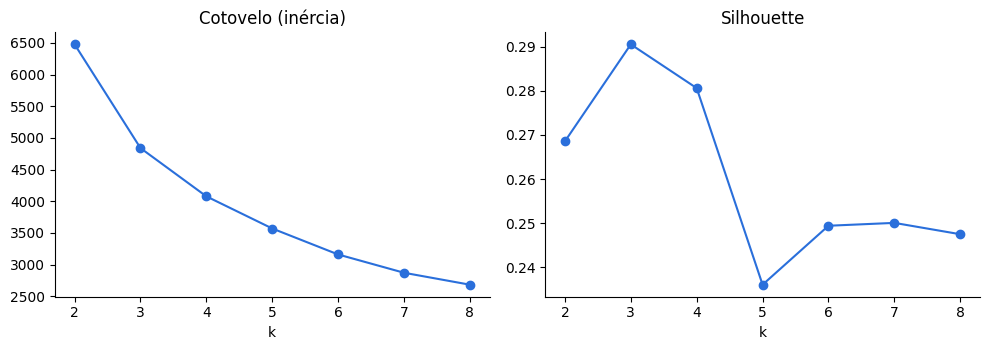

k escolhido: 3 (melhor silhouette)


k,inercia,silhouette
2,6478.288,0.269
3,4839.882,0.291
4,4077.845,0.281
5,3570.224,0.236
6,3160.214,0.249
7,2871.359,0.25
8,2682.887,0.247


In [0]:
amostra = min(len(Xs), 5000)
resultados = []
for k in KMEANS_K_RANGE:
    km = KMeans(n_clusters=k, n_init=20, random_state=KMEANS_SEED).fit(Xs)
    sil = silhouette_score(Xs, km.labels_, sample_size=amostra, random_state=KMEANS_SEED)
    resultados.append({"k": k, "inercia": km.inertia_, "silhouette": sil})
escolha = pd.DataFrame(resultados)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 3.6))
ax1.plot(escolha["k"], escolha["inercia"], marker="o", color="#2a6fdb")
ax1.set_title("Cotovelo (inércia)")
ax1.set_xlabel("k")
ax2.plot(escolha["k"], escolha["silhouette"], marker="o", color="#2a6fdb")
ax2.set_title("Silhouette")
ax2.set_xlabel("k")
for ax in (ax1, ax2):
    ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

K = int(escolha.loc[escolha["silhouette"].idxmax(), "k"]) if K_WIDGET == "auto" else int(K_WIDGET)
print(f"k escolhido: {K} ({'melhor silhouette' if K_WIDGET == 'auto' else 'definido no widget'})")
display(escolha.round(3))

## 6.3. Modelo final

Os clusters são renumerados por agenda mediana (cluster 0 = maior agenda) para que a numeração não mude entre execuções.

Cada cluster recebe um nome automático a partir do seu centro padronizado: variáveis com centro acima de +0,5 desvio viram "alto", abaixo de −0,5 viram "baixo".

In [0]:
km = KMeans(n_clusters=K, n_init=50, random_state=KMEANS_SEED).fit(Xs)
base["cluster_bruto"] = km.labels_

# Renumera: cluster 0 = maior agenda em aberto mediana
ordem = base.groupby("cluster_bruto")["agenda_aberta"].median().sort_values(ascending=False).index
mapa = {bruto: novo for novo, bruto in enumerate(ordem)}
base["cluster"] = base["cluster_bruto"].map(mapa)

centros = pd.DataFrame(km.cluster_centers_, columns=X.columns)
centros.index = [mapa[i] for i in centros.index]
centros = centros.sort_index()

def nome_automatico(linha):
    destaque = linha[linha.abs() >= 0.5].reindex(linha.abs().sort_values(ascending=False).index).dropna()
    partes = [NOMES[v][0] if z > 0 else NOMES[v][1] for v, z in destaque.head(2).items()]
    return " · ".join(partes) if partes else "perfil médio"

# Nomes de negócio definidos após ler o perfil (seção 6.4) e o cruzamento com a regra (6.6).
# Deliberadamente diferentes dos nomes dos segmentos por regra: cluster e segmento não são a
# mesma coisa (ex.: só ~23% do C1 é "Grande ocasional"; 37% são "Grandes parceladores").
NOMES_MANUAIS = {
    0: "Recorrentes com agenda",       # 46% dos lojistas, 61% da agenda, 5 meses ativos, giro rápido (71 d)
    1: "Grandes vendas, longa espera",  # 25% dos lojistas, 38% da agenda, ticket R$ 309, 114 dias, 2 meses ativos
    2: "Baixa atividade",               # 29% dos lojistas, agenda mediana zero, ~1 mês ativo
}

centros["cluster_nome"] = [
    NOMES_MANUAIS.get(c, f"C{c}: {nome_automatico(centros.loc[c, X.columns])}") for c in centros.index
]
base["cluster_nome"] = base["cluster"].map(centros["cluster_nome"])

display(centros.round(2).reset_index().rename(columns={"index": "cluster"}))

cluster,log_agenda_aberta,prazo_medio_contratado_dias,log_ticket_medio,meses_ativos_janela,pct_parcelado,cluster_nome
0,0.56,-0.23,-0.23,0.76,-0.06,Recorrentes com agenda
1,0.25,1.23,1.13,-0.37,0.9,"Grandes vendas, longa espera"
2,-1.13,-0.71,-0.63,-0.9,-0.7,Baixa atividade


## 6.4. Perfil dos clusters

Em unidades de negócio (medianas), não em desvios-padrão.

In [0]:
perfil = (
    base.groupby(["cluster", "cluster_nome"])
    .agg(
        lojistas=("seller_id", "count"),
        agenda_aberta_total=("agenda_aberta", "sum"),
        tpv_total=("tpv_total", "sum"),
        agenda_mediana=("agenda_aberta", "median"),
        ticket_mediano=("ticket_medio", "median"),
        prazo_contratado_mediano=("prazo_medio_contratado_dias", "median"),
        pct_parcelado_mediano=("pct_parcelado", "median"),
        meses_ativos_janela_mediano=("meses_ativos_janela", "median"),
    )
    .reset_index()
)
perfil["pct_lojistas"] = perfil["lojistas"] / perfil["lojistas"].sum()
perfil["pct_agenda"] = perfil["agenda_aberta_total"] / perfil["agenda_aberta_total"].sum()
perfil["pct_tpv"] = perfil["tpv_total"] / perfil["tpv_total"].sum()

display(perfil.round(3))

cluster,cluster_nome,lojistas,agenda_aberta_total,tpv_total,agenda_mediana,ticket_mediano,prazo_contratado_mediano,pct_parcelado_mediano,meses_ativos_janela_mediano,pct_lojistas,pct_agenda,pct_tpv
0,Recorrentes com agenda,864,1432387.205,8977159.579,626.36,123.289,70.88,0.576,5.0,0.461,0.608,0.669
1,"Grandes vendas, longa espera",473,905419.613,3791242.192,551.61,309.381,113.971,0.781,2.0,0.252,0.384,0.282
2,Baixa atividade,538,19330.637,653301.111,0.0,84.402,54.698,0.424,1.0,0.287,0.008,0.049


## 6.5. Visualização em duas dimensões (PCA)

O PCA projeta as cinco variáveis em dois eixos só para enxergar a separação. Grupos sobrepostos aqui podem estar separados nas dimensões que o gráfico não mostra; a silhouette é a medida que vale.

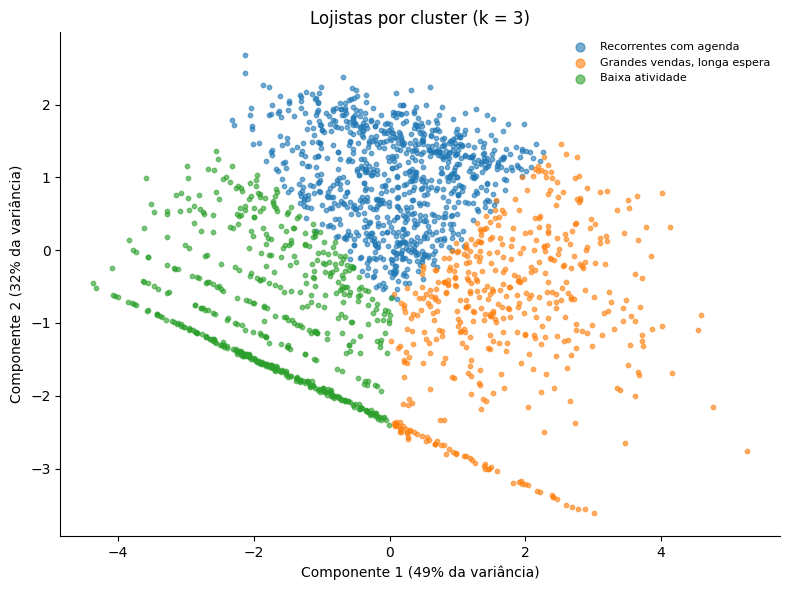

variavel,comp_1,comp_2
log_agenda_aberta,0.4,0.57
prazo_medio_contratado_dias,0.54,-0.26
log_ticket_medio,0.52,-0.2
meses_ativos_janela,0.17,0.73
pct_parcelado,0.5,-0.2


In [0]:
pca = PCA(n_components=2, random_state=KMEANS_SEED)
P = pca.fit_transform(Xs)
cores = plt.get_cmap("tab10")

fig, ax = plt.subplots(figsize=(8, 6))
for c in sorted(base["cluster"].unique()):
    m = (base["cluster"] == c).to_numpy()
    ax.scatter(P[m, 0], P[m, 1], s=10, alpha=0.6, color=cores(c), label=centros.loc[c, "cluster_nome"])
ev = pca.explained_variance_ratio_
ax.set_xlabel(f"Componente 1 ({ev[0]:.0%} da variância)")
ax.set_ylabel(f"Componente 2 ({ev[1]:.0%} da variância)")
ax.set_title(f"Lojistas por cluster (k = {K})")
ax.legend(frameon=False, fontsize=8, loc="best", markerscale=2)
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

# Pesos das variáveis em cada componente, para dizer o que cada eixo significa
display(
    pd.DataFrame(pca.components_.T, index=X.columns, columns=["comp_1", "comp_2"])
    .round(2).rename_axis("variavel").reset_index()
)

## 6.6. K-means vs. segmentação por regra

A tabela cruzada mostra, para cada cluster, de quais segmentos por regra vêm os seus lojistas. O **Adjusted Rand Index (ARI)** resume a concordância: 1 = idênticos, 0 = tão parecidos quanto o acaso.

Como ler:

- Um cluster dominado por um único segmento confirma a regra.
- Um segmento espalhado por vários clusters indica que a regra junta lojistas diferentes; vale abrir esse segmento.
- ARI baixo não é erro: as regras usam cortes de negócio, o k-means usa distância. O valor do exercício está nas diferenças.

cluster_nome,Grandes ocasionais,Grandes parceladores,Médios recorrentes,Pequenos ou esporádicos,À vista
Baixa atividade,0.01,0.0,0.11,0.68,0.2
"Grandes vendas, longa espera",0.23,0.37,0.14,0.25,0.01
Recorrentes com agenda,0.01,0.32,0.6,0.06,0.02


Adjusted Rand Index (regra vs. k-means): 0.30


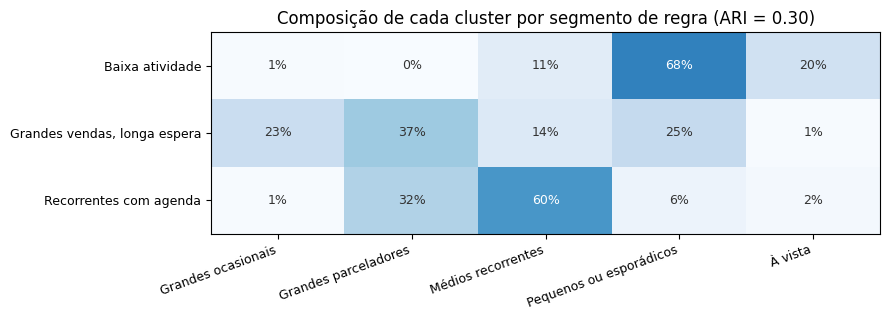

In [0]:
cruzada = pd.crosstab(base["cluster_nome"], base["segmento_regra"], normalize="index")
display(cruzada.round(2).reset_index())

ari = adjusted_rand_score(base["segmento_regra"], base["cluster"])
print(f"Adjusted Rand Index (regra vs. k-means): {ari:.2f}")

fig, ax = plt.subplots(figsize=(9, 0.6 * len(cruzada) + 1.5))
im = ax.imshow(cruzada.to_numpy(), cmap="Blues", vmin=0, vmax=1, aspect="auto")
ax.set_xticks(range(len(cruzada.columns)))
ax.set_xticklabels(cruzada.columns, rotation=20, ha="right", fontsize=9)
ax.set_yticks(range(len(cruzada.index)))
ax.set_yticklabels(cruzada.index, fontsize=9)
for i in range(cruzada.shape[0]):
    for j in range(cruzada.shape[1]):
        v = cruzada.iat[i, j]
        ax.text(j, i, f"{v:.0%}", ha="center", va="center", fontsize=9, color="white" if v > 0.6 else "#333333")
ax.set_title(f"Composição de cada cluster por segmento de regra (ARI = {ari:.2f})")
plt.tight_layout()
plt.show()

## 6.7. Gravar na gold

- `seller_cluster`: um lojista por linha, com cluster, nome e as variáveis usadas.
- `cluster_perfil`: o perfil da seção 6.4, pronto para o dashboard.

Lojistas abaixo do mínimo de pedidos não aparecem em `seller_cluster`.

In [0]:
saida = pd.concat(
    [base[["seller_id", "segmento_regra", "cluster", "cluster_nome"]].reset_index(drop=True),
     X.reset_index(drop=True)],
    axis=1,
)
saida["k"] = K
saida["data_corte"] = pd.to_datetime('2018-06-30').date()

(spark.createDataFrame(saida)
 .write.mode("overwrite").option("overwriteSchema", "true")
 .saveAsTable("workspace.olist.gold_seller_cluster"))

(spark.createDataFrame(perfil.assign(k=K, ari_vs_regra=float(ari)))
 .write.mode("overwrite").option("overwriteSchema", "true")
 .saveAsTable("workspace.olist.gold_cluster_perfil"))

print(f"Gravados workspace.olist.gold_seller_cluster ({len(saida):,} linhas) e workspace.olist.gold_cluster_perfil ({len(perfil)} linhas).")

Gravados workspace.olist.gold_seller_cluster (1,875 linhas) e workspace.olist.gold_cluster_perfil (3 linhas).
